# NHANES 05 - Evaluación final con el conjunto de prueba reservado

Corresponde a la etapa de **Evaluación** del proceso CRISP-DM y a los **objetivos específicos 2 y 3**. Aplica las secciones 11 y 14 de `docs/protocolo_nhanes.md` (etiqueta `protocolo-nhanes-v1.1`).

- Los cuatro modelos, sus hiperparámetros y sus umbrales se congelaron en el notebook 03 (`models/nhanes/`, etiqueta `modelo-nhanes-v1`). **Aquí no se ajusta ni se elige nada.**
- Esta es la **única ejecución** sobre el conjunto de prueba (4,627 participantes de 40 conglomerados de 2007–2016). El registro `registro_ejecucion.json` se escribe **antes** de leer los datos de prueba, con la fecha, el commit y las huellas SHA-256. Si ese registro ya existe, el notebook se detiene.
- Antes de esta ejecución, el código se ensayó con los datos de desarrollo, sin leer el conjunto de prueba.
- Es una **validación interna** con un conjunto reservado, no una validación temporal ni externa.

In [1]:
import json
import subprocess
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from statsmodels.nonparametric.smoothers_lowess import lowess

import preparacion_nhanes as pn
from preparacion_nhanes import DESENLACE, DESENLACE_SECUNDARIO, PREDICTORES

pd.set_option('display.float_format', '{:.4f}'.format)

MODO = 'final'
DATOS = pn.RUTA_PRUEBA
SHA256_PRUEBA_PROTOCOLO = 'c48492938873def3d096e59c8d465e32843fdd574d3dd2b349e90754d58ee62c'  # protocolo, sección 15
SALIDA = Path('../../resultados/nhanes/05_evaluacion_final')
MODELOS = Path('../../models/nhanes')
REGISTRO = SALIDA / 'registro_ejecucion.json'
SEMILLA, N_BOOTSTRAP = 42, 2000

if REGISTRO.exists():
    raise RuntimeError(f'La evaluación final ya se ejecutó (ver {REGISTRO}). El protocolo permite una sola ejecución.')

estado_git = subprocess.run(['git', 'status', '--porcelain', '--', str(MODELOS)], capture_output=True, text=True).stdout
if estado_git.strip():
    raise RuntimeError('Los modelos tienen cambios sin commit; no se puede garantizar que estén congelados.')
commit = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
print('Modo:', MODO, '| commit:', commit)

Modo: final | commit: aa31a1f


## Verificación de huellas y registro de la ejecución

Se comprueba que los modelos sean los congelados (SHA-256 de `registro_modelos.csv`), que se entrenaron con el desarrollo y la partición vigentes, y que el archivo de prueba sea el mismo cuya huella se anotó en el protocolo al crear la partición. El registro se escribe en este punto, antes de leer los datos.

In [2]:
registro_modelos = pd.read_csv(MODELOS / 'registro_modelos.csv').set_index('archivo')
artefactos = {}
for archivo, fila in registro_modelos.iterrows():
    ruta = MODELOS / archivo
    assert pn.sha256(ruta) == fila['sha256'], f'{archivo} no coincide con el modelo congelado'
    a = joblib.load(ruta)
    assert a['sha256_desarrollo'] == pn.sha256(pn.RUTA_DESARROLLO) and a['sha256_particion'] == pn.sha256(pn.RUTA_PARTICION)
    artefactos[a['algoritmo']] = a | {'archivo': archivo}

huella_datos = pn.sha256(DATOS)
if MODO == 'final':
    assert huella_datos == SHA256_PRUEBA_PROTOCOLO, 'el archivo de prueba no es el registrado en el protocolo'

SALIDA.mkdir(parents=True, exist_ok=True)
registro = {
    'modo': MODO,
    'inicio': datetime.now().isoformat(timespec='seconds'),
    'commit': commit,
    'datos': DATOS.name,
    'datos_sha256': huella_datos,
    'modelos_sha256': registro_modelos['sha256'].to_dict(),
    'estado': 'iniciada',
}
REGISTRO.write_text(json.dumps(registro, indent=2), encoding='utf-8')
pd.DataFrame([{'algoritmo': n, 'archivo': a['archivo'], 'seleccionado': a['seleccionado'], 'umbral': a['umbral'],
               'AUC_CV': a['auc_cv']} for n, a in artefactos.items()])

,algoritmo,archivo,seleccionado,umbral,AUC_CV
0,Regresión logística,regresion_logistica.joblib,True,0.2766,0.7546
1,Random Forest,random_forest.joblib,False,0.2926,0.7504
2,XGBoost,xgboost.joblib,False,0.2918,0.7523
3,LightGBM,lightgbm.joblib,False,0.2924,0.7519


## Datos y predicciones

In [3]:
t = pd.read_csv(DATOS)
y = t[DESENLACE].astype(int).to_numpy()
y_dm = t[DESENLACE_SECUNDARIO].astype(int).to_numpy()
conglomerados = t['conglomerado'].to_numpy()
PREVALENCIA_DESARROLLO = artefactos['Regresión logística']['prevalencia_desarrollo']  # modelo nulo

pred = {n: a['modelo'].predict_proba(t[a['predictores']])[:, 1] for n, a in artefactos.items()}
SELECCIONADO = next(n for n, a in artefactos.items() if a['seleccionado'])
print(f'{len(t):,} participantes, {t.conglomerado.nunique()} conglomerados | HbA1c >= 5.7: {y.sum():,} ({100 * y.mean():.2f}%) | '
      f'HbA1c >= 6.5: {y_dm.sum():,} ({100 * y_dm.mean():.2f}%)')
print(f'Datos faltantes imputados por el pipeline: {int(t[PREDICTORES].isna().sum().sum())} valores')
print('Modelo seleccionado:', SELECCIONADO)

4,627 participantes, 40 conglomerados | HbA1c >= 5.7: 1,235 (26.69%) | HbA1c >= 6.5: 104 (2.25%)
Datos faltantes imputados por el pipeline: 330 valores
Modelo seleccionado: Regresión logística


## Métricas de desempeño

- AUC-ROC y AUC-PR con IC 95 % por **bootstrap por conglomerado** (2,000 remuestreos de los conglomerados de prueba; los mismos remuestreos para todos los modelos).
- Sensibilidad, especificidad, VPP y VPN en el umbral congelado.
- Calibración: pendiente, razón O/E e intercepto con IC 95 % bootstrap, e ICI (sin IC); Brier frente al modelo nulo (prevalencia del desarrollo).
- Consistencia: AUC de validación cruzada menos AUC de prueba.

In [4]:
rng = np.random.default_rng(SEMILLA)
lista_cong = np.unique(conglomerados)
filas_de = {c: np.flatnonzero(conglomerados == c) for c in lista_cong}
REMUESTREOS = [np.concatenate([filas_de[c] for c in rng.choice(lista_cong, len(lista_cong), replace=True)])
               for _ in range(N_BOOTSTRAP)]


def calibracion(y_real, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p))
    pendiente = sm.Logit(y_real, sm.add_constant(lp)).fit(disp=False).params[1]
    intercepto = sm.GLM(y_real, np.ones(len(lp)), offset=lp, family=sm.families.Binomial()).fit().params[0]
    return {'pendiente': pendiente, 'O/E': y_real.mean() / p.mean(), 'intercepto': intercepto}


def ici(y_real, p):
    # Índice de calibración integrado: solo se reporta, sin IC (el lowess es costoso en 2,000 remuestreos)
    suavizada = lowess(y_real, p, frac=2 / 3, it=0, return_sorted=False)
    return np.mean(np.abs(suavizada - p))


def ic(funcion, y_real, p):
    valores = np.array([funcion(y_real[i], p[i]) for i in REMUESTREOS if 0 < y_real[i].sum() < len(i)])
    return np.percentile(valores, [2.5, 97.5], axis=0)


def clasificacion(y_real, p, umbral):
    positivo = p >= umbral
    vp, fp = (positivo & (y_real == 1)).sum(), (positivo & (y_real == 0)).sum()
    vn, fn = (~positivo & (y_real == 0)).sum(), (~positivo & (y_real == 1)).sum()
    return {'sensibilidad': vp / (vp + fn), 'especificidad': vn / (vn + fp), 'VPP': vp / (vp + fp), 'VPN': vn / (vn + fn)}


def fmt(a, b, d=3):
    return f'{a:.{d}f}–{b:.{d}f}'


filas = []
for nombre, a in artefactos.items():
    p = pred[nombre]
    auc_ic, ap_ic = ic(roc_auc_score, y, p), ic(average_precision_score, y, p)
    cal = calibracion(y, p)
    cal_ic = ic(lambda yy, pp: list(calibracion(yy, pp).values()), y, p)
    filas.append({
        'algoritmo': nombre, 'seleccionado': a['seleccionado'],
        'AUC_ROC': roc_auc_score(y, p), 'AUC_ROC_IC95': fmt(*auc_ic),
        'AUC_PR': average_precision_score(y, p), 'AUC_PR_IC95': fmt(*ap_ic),
        **clasificacion(y, p, a['umbral']),
        'Brier': brier_score_loss(y, p), 'Brier_nulo': brier_score_loss(y, np.full(len(y), PREVALENCIA_DESARROLLO)),
        'pendiente': cal['pendiente'], 'pendiente_IC95': fmt(cal_ic[0][0], cal_ic[1][0], 2),
        'O/E': cal['O/E'], 'O/E_IC95': fmt(cal_ic[0][1], cal_ic[1][1], 2),
        'intercepto': cal['intercepto'], 'intercepto_IC95': fmt(cal_ic[0][2], cal_ic[1][2], 2),
        'ICI': ici(y, p),
        'AUC_CV': a['auc_cv'], 'AUC_CV_menos_prueba': a['auc_cv'] - roc_auc_score(y, p),
    })
resultados = pd.DataFrame(filas)
resultados.to_csv(SALIDA / 'metricas_prueba.csv', index=False)
resultados.T

,0,1,2,3
algoritmo,Regresión logística,Random Forest,XGBoost,LightGBM
seleccionado,True,False,False,False
AUC_ROC,0.7436,0.7419,0.7450,0.7452
AUC_ROC_IC95,0.730–0.757,0.729–0.755,0.732–0.758,0.732–0.758
AUC_PR,0.4828,0.4689,0.4800,0.4784
AUC_PR_IC95,0.448–0.515,0.436–0.500,0.446–0.511,0.445–0.509
sensibilidad,0.6753,0.6850,0.6891,0.6947
especificidad,0.6916,0.6798,0.6863,0.6831
VPP,0.4436,0.4379,0.4444,0.4439
VPN,0.8540,0.8557,0.8584,0.8601


## Comparación de algoritmos con la regresión logística (HE2)

Prueba de DeLong bilateral para AUC-ROC correlacionadas (mismos participantes), con el algoritmo rápido de Sun y Xu (2014). **La prueba supone independencia entre observaciones**, lo que no se cumple del todo con participantes agrupados en conglomerados; por eso se reporta también la diferencia de AUC con su IC 95 % por bootstrap por conglomerado.

In [5]:
def _rangos_medios(x):
    orden = np.argsort(x)
    z = x[orden]
    n = len(x)
    rangos_ordenados = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        rangos_ordenados[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    rangos = np.empty(n)
    rangos[orden] = rangos_ordenados
    return rangos


def delong(y_real, p1, p2):
    positivos, negativos = y_real == 1, y_real == 0
    m, n = positivos.sum(), negativos.sum()
    predicciones = np.vstack([p1, p2])
    tx = np.array([_rangos_medios(k[positivos]) for k in predicciones])
    ty = np.array([_rangos_medios(k[negativos]) for k in predicciones])
    tz = np.array([_rangos_medios(np.concatenate([k[positivos], k[negativos]])) for k in predicciones])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1) / 2 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var)
    return aucs[0] - aucs[1], 2 * stats.norm.sf(abs(z))


# Comprobación de la implementación: la AUC de DeLong coincide con la de scikit-learn
dif_control, _ = delong(y, pred['XGBoost'], pred['Regresión logística'])
assert abs(dif_control - (roc_auc_score(y, pred['XGBoost']) - roc_auc_score(y, pred['Regresión logística']))) < 1e-10

filas = []
for nombre in artefactos:
    if nombre == 'Regresión logística':
        continue
    dif, p_valor = delong(y, pred[nombre], pred['Regresión logística'])
    dif_ic = np.percentile([roc_auc_score(y[i], pred[nombre][i]) - roc_auc_score(y[i], pred['Regresión logística'][i])
                            for i in REMUESTREOS], [2.5, 97.5])
    filas.append({'algoritmo': nombre, 'AUC_algoritmo_menos_AUC_RL': dif, 'IC95_bootstrap_conglomerado': fmt(*dif_ic, 4),
                  'p_DeLong': p_valor, 'diferencia_significativa (p < 0.05)': 'Sí' if p_valor < 0.05 else 'No'})
he2 = pd.DataFrame(filas)
he2.to_csv(SALIDA / 'he2_delong.csv', index=False)
he2

,algoritmo,AUC_algoritmo_menos_AUC_RL,IC95_bootstrap_conglomerado,p_DeLong,diferencia_significativa (p < 0.05)
0,Random Forest,-0.0017,-0.0063–0.0033,0.4610,No
1,XGBoost,0.0013,-0.0019–0.0048,0.3849,No
2,LightGBM,0.0015,-0.0015–0.0048,0.3709,No


## Curva de calibración

Proporción observada de HbA1c ≥ 5.7 % frente a la probabilidad media predicha, por deciles de probabilidad, con la curva suavizada (lowess) del modelo seleccionado.

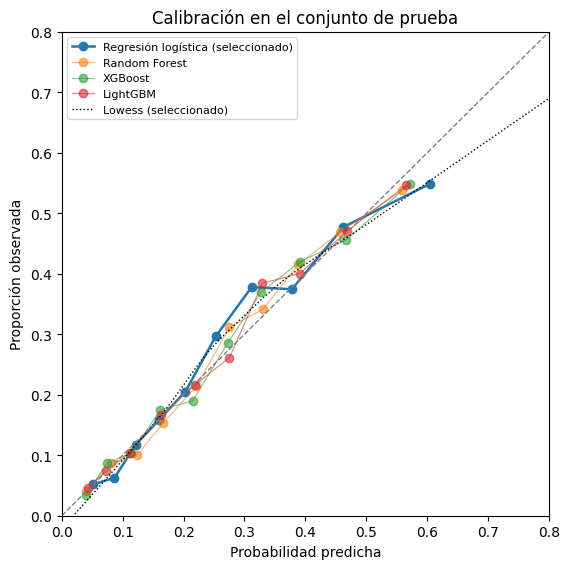

In [6]:
fig, ax = plt.subplots(figsize=(5.8, 5.8))
for nombre, p in pred.items():
    deciles = pd.qcut(p, 10, labels=False, duplicates='drop')
    g = pd.DataFrame({'p': p, 'y': y, 'd': deciles}).groupby('d').agg(predicha=('p', 'mean'), observada=('y', 'mean'), n=('y', 'size'))
    if nombre == SELECCIONADO:
        g.to_csv(SALIDA / 'calibracion_deciles_seleccionado.csv')
    ax.plot(g['predicha'], g['observada'], marker='o', lw=1.8 if nombre == SELECCIONADO else 0.8,
            alpha=1 if nombre == SELECCIONADO else 0.6, label=nombre + (' (seleccionado)' if nombre == SELECCIONADO else ''))
orden = np.argsort(pred[SELECCIONADO])
suave = lowess(y, pred[SELECCIONADO], frac=2 / 3, it=0, return_sorted=False)
ax.plot(pred[SELECCIONADO][orden], suave[orden], color='black', lw=1, ls=':', label='Lowess (seleccionado)')
ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1)
ax.set(xlim=(0, 0.8), ylim=(0, 0.8), xlabel='Probabilidad predicha', ylabel='Proporción observada',
       title='Calibración en el conjunto de prueba')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(SALIDA / 'curva_calibracion.png', dpi=150)
plt.show()

## Análisis secundarios

1. **HbA1c ≥ 6.5 %** (compatible con diabetes): capacidad del modelo seleccionado para ordenar a las personas según este desenlace. Solo se reportan la AUC-ROC y la AUC-PR, porque el modelo estima la probabilidad de HbA1c ≥ 5.7 % y su calibración no aplica a este otro desenlace.
2. **Por sexo y grupo de edad** (20–39, 40–59, 60–69): AUC-ROC, pendiente y razón O/E del modelo seleccionado.

In [7]:
p_sel = pred[SELECCIONADO]
secundario = pd.DataFrame([{
    'desenlace': 'HbA1c >= 6.5 %', 'casos': int(y_dm.sum()),
    'AUC_ROC': roc_auc_score(y_dm, p_sel), 'AUC_ROC_IC95': fmt(*ic(roc_auc_score, y_dm, p_sel)),
    'AUC_PR': average_precision_score(y_dm, p_sel), 'prevalencia': y_dm.mean(),
}])
secundario.to_csv(SALIDA / 'secundario_hba1c_6_5.csv', index=False)
secundario

,desenlace,casos,AUC_ROC,AUC_ROC_IC95,AUC_PR,prevalencia
0,HbA1c >= 6.5 %,104,0.7904,0.757–0.822,0.0804,0.0225


In [8]:
grupos = {
    'Mujeres': t['hombre'] == 0, 'Hombres': t['hombre'] == 1,
    'Edad 20-39': t['edad'].between(20, 39), 'Edad 40-59': t['edad'].between(40, 59), 'Edad 60-69': t['edad'].between(60, 69),
}
filas = []
for nombre, m in grupos.items():
    m = m.to_numpy()
    cal = calibracion(y[m], p_sel[m])
    filas.append({'subgrupo': nombre, 'n': int(m.sum()), 'prevalencia': y[m].mean(), 'AUC_ROC': roc_auc_score(y[m], p_sel[m]),
                  'pendiente': cal['pendiente'], 'O/E': cal['O/E']})
subgrupos = pd.DataFrame(filas)
subgrupos.to_csv(SALIDA / 'subgrupos.csv', index=False)
subgrupos

,subgrupo,n,prevalencia,AUC_ROC,pendiente,O/E
0,Mujeres,2365,0.2579,0.7647,1.0672,1.0468
1,Hombres,2262,0.2763,0.7224,0.8951,0.9856
2,Edad 20-39,1992,0.1315,0.7053,1.0245,0.9853
3,Edad 40-59,1899,0.3286,0.6778,1.0763,1.0653
4,Edad 60-69,736,0.4742,0.5725,0.5228,0.9556


## Interpretación del modelo en el conjunto de prueba (SHAP)

En la regresión logística con variables estandarizadas, los valores SHAP exactos en log-odds son coeficiente × valor estandarizado (respecto de la media del desarrollo). Se reporta la media del valor absoluto por factor, sumando IMC y perímetro abdominal como en la web.

In [9]:
modelo_sel = artefactos[SELECCIONADO]['modelo']
if SELECCIONADO == 'Regresión logística':
    prep, rl = modelo_sel.named_steps['prep'], modelo_sel.named_steps['modelo']
    columnas = [c.split('__', 1)[1] for c in prep.get_feature_names_out()]
    valores_shap = pd.DataFrame(prep.transform(t[PREDICTORES]) * rl.coef_[0], columns=columnas)
    valores_shap['composicion_corporal'] = valores_shap.pop('imc') + valores_shap.pop('cintura')
    shap_prueba = valores_shap.abs().mean().sort_values(ascending=False).rename('media_abs_SHAP_log_odds').to_frame()
    shap_prueba.to_csv(SALIDA / 'shap_prueba.csv')
    display(shap_prueba)

,media_abs_SHAP_log_odds
edad,0.6745
composicion_corporal,0.3690
hombre,0.1292
actividad,0.1152
familiar_dm,0.1144
fuma,0.0976
hta,0.0137


## Contrastación de HE3 (metas fijadas el 2026-10-21, sección 14 del protocolo)

In [10]:
s = resultados.set_index('algoritmo').loc[SELECCIONADO]
he3 = pd.DataFrame([
    {'criterio': 'AUC-ROC >= 0.75', 'valor': f"{s['AUC_ROC']:.3f} (IC95 {s['AUC_ROC_IC95']})", 'cumple': s['AUC_ROC'] >= 0.75},
    {'criterio': 'Pendiente de calibración entre 0.8 y 1.2', 'valor': f"{s['pendiente']:.2f} (IC95 {s['pendiente_IC95']})", 'cumple': 0.8 <= s['pendiente'] <= 1.2},
    {'criterio': 'Razón O/E entre 0.9 y 1.1', 'valor': f"{s['O/E']:.3f} (IC95 {s['O/E_IC95']})", 'cumple': 0.9 <= s['O/E'] <= 1.1},
    {'criterio': 'Brier menor que el del modelo nulo', 'valor': f"{s['Brier']:.4f} frente a {s['Brier_nulo']:.4f}", 'cumple': s['Brier'] < s['Brier_nulo']},
])
he3['cumple'] = he3['cumple'].map({True: 'Sí', False: 'No'})
he3.to_csv(SALIDA / 'he3.csv', index=False)
print('Modelo seleccionado:', SELECCIONADO, '| intercepto', f"{s['intercepto']:.3f} ({s['intercepto_IC95']}) | ICI {s['ICI']:.4f} (solo se reportan)")
he3

Modelo seleccionado: Regresión logística | intercepto 0.024 (-0.09–0.13) | ICI 0.0192 (solo se reportan)


,criterio,valor,cumple
0,AUC-ROC >= 0.75,0.744 (IC95 0.730–0.757),No
1,Pendiente de calibración entre 0.8 y 1.2,0.98 (IC95 0.91–1.05),Sí
2,Razón O/E entre 0.9 y 1.1,1.015 (IC95 0.95–1.08),Sí
3,Brier menor que el del modelo nulo,0.1687 frente a 0.1957,Sí


## Cierre del registro

El registro pasa a estado `completa`. El notebook no puede volver a ejecutarse.

In [11]:
registro.update({'fin': datetime.now().isoformat(timespec='seconds'), 'estado': 'completa',
                 'modelo_seleccionado': SELECCIONADO, 'AUC_ROC_seleccionado': round(float(s['AUC_ROC']), 4)})
REGISTRO.write_text(json.dumps(registro, indent=2), encoding='utf-8')
registro

{'modo': 'final',
 'inicio': '2026-10-21T23:23:49',
 'commit': 'aa31a1f',
 'datos': 'nhanes_prueba.csv',
 'datos_sha256': 'c48492938873def3d096e59c8d465e32843fdd574d3dd2b349e90754d58ee62c',
 'modelos_sha256': {'regresion_logistica.joblib': 'fa1be5d6a0ab00640f41549cd27725aa975f555fd55e02ffb2e434a57d41dd1b',
  'random_forest.joblib': 'cb8313814e6b276f347699b448c7904be173b8d41e6de045c8c493789905fb4b',
  'xgboost.joblib': '79c170f4c7e2972fd7cc3c899ed2347f1bcfafcc861529a086b1cebfc8682b83',
  'lightgbm.joblib': '2059531018f27a9467f6232e007ba25629f098c729431e58945ffaf5254d2bfb'},
 'estado': 'completa',
 'fin': '2026-10-21T23:26:53',
 'modelo_seleccionado': 'Regresión logística',
 'AUC_ROC_seleccionado': 0.7436}

## Interpretación

*Celda de texto agregada después de la única ejecución; el notebook no se volvió a ejecutar.*

**HE3: se cumple parcialmente.**

- **Discriminación:** el modelo seleccionado (regresión logística) obtuvo una AUC-ROC de **0.744** (IC 95 % 0.730–0.757) en el conjunto de prueba. Queda **por debajo de la meta prefijada de 0.75**, aunque el intervalo de confianza incluye ese valor. Conforme al protocolo, la meta se considera **no alcanzada** y el modelo **no se modifica** para acercarlo a ella.
- **Calibración:** cumple los tres criterios prefijados. Pendiente 0.98 (0.91–1.05), razón O/E 1.015 (0.95–1.08) y Brier de 0.169, frente a 0.196 del modelo nulo. La curva por deciles sigue la diagonal en todo el rango de probabilidades predichas (5 % a 60 %).
- **Consistencia con el desarrollo:** la AUC de prueba es 0.011 menor que la de validación cruzada (0.755). Es una diferencia pequeña, compatible con el optimismo esperable y con la variación entre conglomerados.

**HE2: no se confirma.** Ningún algoritmo de ensamble difiere de la regresión logística: las diferencias de AUC van de −0.002 a +0.002, con p de DeLong entre 0.37 y 0.46, y todos los intervalos bootstrap por conglomerado incluyen el cero. Con estos ocho predictores no invasivos, Random Forest, XGBoost y LightGBM no mejoran la discriminación del modelo lineal. Esto respalda la elección por parsimonia e interpretabilidad.

**Resultados secundarios.**

- Para HbA1c ≥ 6.5 % (compatible con diabetes), el modelo ordena mejor a las personas: AUC 0.790 (0.757–0.822). Esta cifra se basa en solo 104 casos.
- La discriminación es mayor en mujeres (0.765) que en hombres (0.722), y disminuye con la edad: 0.705 entre 20 y 39 años, 0.678 entre 40 y 59, y **0.573 entre 60 y 69**. Como la edad es el predictor más influyente, dentro de un grupo de edad estrecho el modelo dispone de menos información para distinguir. En el grupo de 60 a 69 años (n = 736), la pendiente de 0.52 indica además que las probabilidades son demasiado extremas dentro de ese grupo, aunque la calibración global del grupo es adecuada (O/E 0.96). Esta limitación debe declararse en la discusión y en el sistema web.

**SHAP en la prueba:** el orden de importancia coincide con el del desarrollo. La edad y la composición corporal dominan, y la hipertensión aporta muy poco.

**Alcance.** Es una validación interna con un conjunto de prueba reservado de NHANES 2007–2016, no una validación temporal ni externa. El desempeño en población de Lima Metropolitana no se ha evaluado.


## Interpretación complementaria de la AUC-ROC

*Celda de texto agregada después de la única ejecución.*

HE3 se contrasta con la meta prefijada (AUC-ROC ≥ 0.75), que **no se alcanzó** (0.744; IC 95 % 0.730–0.757). Para interpretar ese valor, sin usarlo como criterio de contraste:

- Según la clasificación convencional (Hosmer, Lemeshow y Sturdivant, 2013; Mandrekar, 2010), una AUC-ROC entre 0.70 y 0.80 corresponde a una discriminación *aceptable*.
- La escala no invasiva FINDRISC obtuvo una AUC de 0.67 para detectar prediabetes en NHANES 1999–2010 (Zhang et al., 2014) y de 0.69 en población peruana (Bernabé-Ortiz et al., 2018). Los desenlaces y las poblaciones no son idénticos a los de este estudio.

(En el protocolo, sección 14.1, consta que el 2026-10-21 se añadió y el 2026-10-22 se retiró un criterio enmendado con este rango.)
